gcn on cora: implemented from scratch and with pytorch geometric

install pytorch geometric

In [1]:
!pip install torch_geometric -q


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


import all the libraries we need

In [2]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import networkx as nx
import matplotlib.pyplot as plt
from torch_geometric.datasets import Planetoid
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.utils import to_networkx
from torch_geometric.nn import GCNConv

/Users/ashishmeshram/Desktop/Master-Project/My-Implementation/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


fix the random seed so results are reproducible

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(42)

load the full cora dataset

In [4]:
dataset = Planetoid(root="data/Cora", name="Cora", transform=NormalizeFeatures())
data = dataset[0]

print basic statistics about the dataset

In [5]:
def print_dataset_stats(dataset, data):
    print("number of graphs:", len(dataset))
    print("number of nodes:", data.num_nodes)
    print("number of edges:", data.num_edges)
    print("number of features per node:", dataset.num_features)
    print("number of classes:", dataset.num_classes)
    print("training nodes:", int(data.train_mask.sum()))
    print("validation nodes:", int(data.val_mask.sum()))
    print("test nodes:", int(data.test_mask.sum()))

print_dataset_stats(dataset, data)

number of graphs: 1
number of nodes: 2708
number of edges: 10556
number of features per node: 1433
number of classes: 7
training nodes: 140
validation nodes: 500
test nodes: 1000


visualize a small connected sample of the cora graph, colored by class

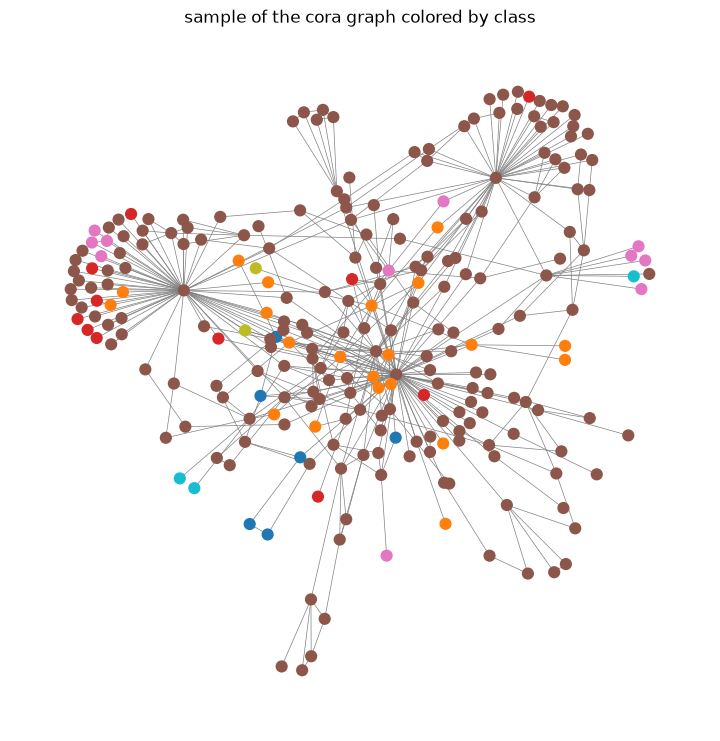

In [6]:
def plot_sample_graph(data, num_nodes=250, start_node=0, seed=42):
    g = to_networkx(data, to_undirected=True)
    sample_nodes = list(nx.bfs_tree(g, start_node))[:num_nodes]
    subgraph = g.subgraph(sample_nodes)
    colors = [data.y[node].item() for node in subgraph.nodes()]
    pos = nx.spring_layout(subgraph, seed=seed)
    plt.figure(figsize=(7, 7))
    nx.draw(subgraph, pos, node_color=colors, cmap="tab10", node_size=60, edge_color="gray", width=0.5)
    plt.title("sample of the cora graph colored by class")
    plt.show()

plot_sample_graph(data)

build a dense adjacency matrix from the edge index

In [7]:
def build_adjacency_matrix(edge_index, num_nodes):
    A = torch.zeros((num_nodes, num_nodes))
    A[edge_index[0], edge_index[1]] = 1
    return A

add self loops to the adjacency matrix so every node keeps its own features

In [8]:
def add_self_loops(A):
    return A + torch.eye(A.shape[0])

normalize the adjacency matrix using the symmetric gcn normalization

In [9]:
def normalize_adjacency(A):
    degree = A.sum(dim=1)
    d_inv_sqrt = torch.pow(degree, -0.5)
    d_inv_sqrt[torch.isinf(d_inv_sqrt)] = 0
    D_inv_sqrt = torch.diag(d_inv_sqrt)
    return D_inv_sqrt @ A @ D_inv_sqrt

put the three steps together to get the final propagation matrix

In [10]:
A = build_adjacency_matrix(data.edge_index, data.num_nodes)
A = add_self_loops(A)
A_hat = normalize_adjacency(A)

define a single gcn layer as a propagate-then-transform operation

In [11]:
def gcn_layer(X, A_hat, W):
    return A_hat @ X @ W

define the gcn model built completely from scratch

In [12]:
class ScratchGCN(nn.Module):
    def __init__(self, in_features, hidden_features, out_features):
        super().__init__()
        self.W1 = nn.Parameter(torch.randn(in_features, hidden_features) * 0.01)
        self.W2 = nn.Parameter(torch.randn(hidden_features, out_features) * 0.01)
        self.dropout = nn.Dropout(0.5)

    def forward(self, X, A_hat):
        H = gcn_layer(X, A_hat, self.W1)
        H = F.relu(H)
        H = self.dropout(H)
        out = gcn_layer(H, A_hat, self.W2)
        return out

create the scratch model, optimizer and loss function

In [13]:
scratch_model = ScratchGCN(dataset.num_features, 16, dataset.num_classes)
scratch_optimizer = torch.optim.Adam(scratch_model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()

define a function that trains the scratch gcn for one epoch

In [14]:
def train_one_epoch_scratch(model, data, A_hat, optimizer):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, A_hat)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

define a function that measures accuracy on train, validation and test nodes

In [15]:
def test_scratch(model, data, A_hat):
    model.eval()
    with torch.no_grad():
        out = model(data.x, A_hat)
        pred = out.argmax(dim=1)
        accuracies = []
        for mask in [data.train_mask, data.val_mask, data.test_mask]:
            correct = (pred[mask] == data.y[mask]).sum()
            accuracies.append(int(correct) / int(mask.sum()))
    return accuracies

train the scratch gcn on cora and keep track of the loss

In [16]:
scratch_losses = []
for epoch in range(200):
    loss = train_one_epoch_scratch(scratch_model, data, A_hat, scratch_optimizer)
    scratch_losses.append(loss)
    if epoch % 20 == 0:
        train_acc, val_acc, test_acc = test_scratch(scratch_model, data, A_hat)
        print(f"epoch {epoch} loss {loss:.4f} train {train_acc:.4f} val {val_acc:.4f} test {test_acc:.4f}")

scratch_final_acc = test_scratch(scratch_model, data, A_hat)

epoch 0 loss 1.9459 train 0.4643 val 0.1980 test 0.2420
epoch 20 loss 1.8627 train 0.7214 val 0.3720 test 0.3820
epoch 40 loss 1.5492 train 0.8286 val 0.4780 test 0.4930
epoch 60 loss 1.1762 train 0.9143 val 0.6420 test 0.6580
epoch 80 loss 0.9019 train 0.9571 val 0.7200 test 0.7390
epoch 100 loss 0.6979 train 0.9786 val 0.7460 test 0.7710
epoch 120 loss 0.5651 train 0.9857 val 0.7660 test 0.7830
epoch 140 loss 0.5467 train 0.9857 val 0.7780 test 0.7920
epoch 160 loss 0.4361 train 0.9857 val 0.7820 test 0.8010
epoch 180 loss 0.4327 train 0.9929 val 0.7800 test 0.8030


plot the training loss curve of the scratch gcn

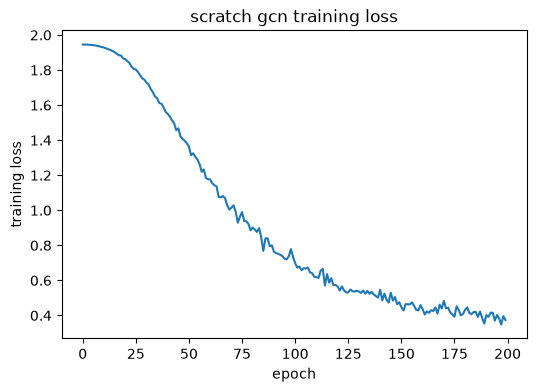

In [17]:
def plot_loss_curve(losses, title):
    plt.figure(figsize=(6, 4))
    plt.plot(losses)
    plt.xlabel("epoch")
    plt.ylabel("training loss")
    plt.title(title)
    plt.show()

plot_loss_curve(scratch_losses, "scratch gcn training loss")

build the same gcn using pytorch geometric's gcnconv layer

In [18]:
class PygGCN(nn.Module):
    def __init__(self, in_features, hidden_features, out_features):
        super().__init__()
        self.conv1 = GCNConv(in_features, hidden_features)
        self.conv2 = GCNConv(hidden_features, out_features)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        h = self.dropout(h)
        out = self.conv2(h, edge_index)
        return out

create the pyg model, optimizer and loss function

In [19]:
pyg_model = PygGCN(dataset.num_features, 16, dataset.num_classes)
pyg_optimizer = torch.optim.Adam(pyg_model.parameters(), lr=0.01, weight_decay=5e-4)

define a function that trains the pyg gcn for one epoch

In [20]:
def train_one_epoch_pyg(model, data, optimizer):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()

define a function that measures accuracy on train, validation and test nodes

In [21]:
def test_pyg(model, data):
    model.eval()
    with torch.no_grad():
        out = model(data.x, data.edge_index)
        pred = out.argmax(dim=1)
        accuracies = []
        for mask in [data.train_mask, data.val_mask, data.test_mask]:
            correct = (pred[mask] == data.y[mask]).sum()
            accuracies.append(int(correct) / int(mask.sum()))
    return accuracies

train the pyg gcn on cora and keep track of the loss

In [22]:
pyg_losses = []
for epoch in range(200):
    loss = train_one_epoch_pyg(pyg_model, data, pyg_optimizer)
    pyg_losses.append(loss)
    if epoch % 20 == 0:
        train_acc, val_acc, test_acc = test_pyg(pyg_model, data)
        print(f"epoch {epoch} loss {loss:.4f} train {train_acc:.4f} val {val_acc:.4f} test {test_acc:.4f}")

pyg_final_acc = test_pyg(pyg_model, data)

epoch 0 loss 1.9461 train 0.3071 val 0.2380 test 0.2090
epoch 20 loss 1.6739 train 0.8500 val 0.5700 test 0.5840
epoch 40 loss 1.3025 train 0.9643 val 0.6860 test 0.7230
epoch 60 loss 0.9518 train 0.9857 val 0.7560 test 0.7930
epoch 80 loss 0.6974 train 0.9929 val 0.7740 test 0.8120
epoch 100 loss 0.5560 train 0.9929 val 0.7800 test 0.8230
epoch 120 loss 0.5131 train 0.9929 val 0.7720 test 0.8140
epoch 140 loss 0.3880 train 0.9929 val 0.7900 test 0.8130
epoch 160 loss 0.3864 train 0.9929 val 0.7900 test 0.8090
epoch 180 loss 0.3301 train 0.9929 val 0.7920 test 0.8050


plot the training loss curve of the pyg gcn

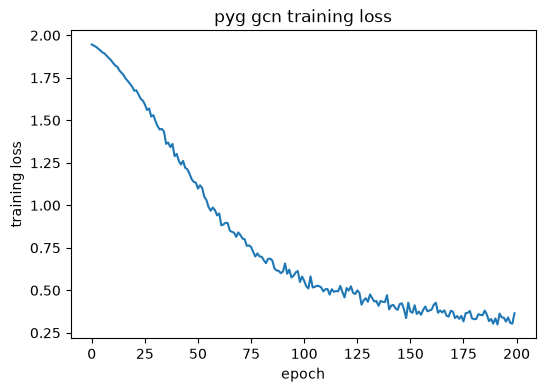

In [23]:
plot_loss_curve(pyg_losses, "pyg gcn training loss")

compare the test accuracy of the scratch gcn and the pyg gcn

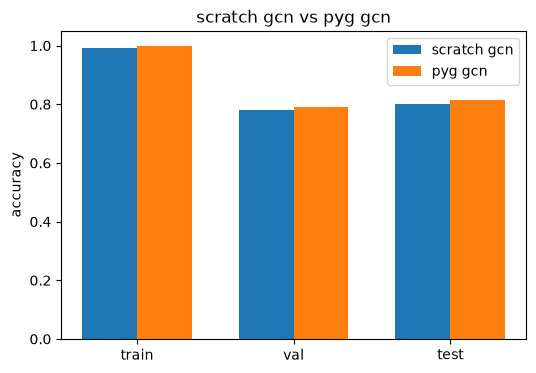

In [24]:
def plot_accuracy_comparison(scratch_acc, pyg_acc):
    labels = ["train", "val", "test"]
    x = np.arange(len(labels))
    width = 0.35
    plt.figure(figsize=(6, 4))
    plt.bar(x - width / 2, scratch_acc, width, label="scratch gcn")
    plt.bar(x + width / 2, pyg_acc, width, label="pyg gcn")
    plt.xticks(x, labels)
    plt.ylabel("accuracy")
    plt.title("scratch gcn vs pyg gcn")
    plt.legend()
    plt.show()

plot_accuracy_comparison(scratch_final_acc, pyg_final_acc)

experiment: build a gcn with a chosen number of layers using pytorch geometric

In [25]:
class DeepPygGCN(nn.Module):
    def __init__(self, in_features, hidden_features, out_features, num_layers):
        super().__init__()
        self.layers = nn.ModuleList()
        if num_layers == 1:
            self.layers.append(GCNConv(in_features, out_features))
        else:
            self.layers.append(GCNConv(in_features, hidden_features))
            for _ in range(num_layers - 2):
                self.layers.append(GCNConv(hidden_features, hidden_features))
            self.layers.append(GCNConv(hidden_features, out_features))
        self.dropout = nn.Dropout(0.5)

    def forward(self, x, edge_index):
        for layer in self.layers[:-1]:
            x = layer(x, edge_index)
            x = F.relu(x)
            x = self.dropout(x)
        x = self.layers[-1](x, edge_index)
        return x

define a function that builds, trains and tests one gcn of a given depth

In [26]:
def run_gcn_with_depth(num_layers, epochs=100):
    set_seed(42)
    model = DeepPygGCN(dataset.num_features, 16, dataset.num_classes, num_layers)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    for epoch in range(epochs):
        train_one_epoch_pyg(model, data, optimizer)
    train_acc, val_acc, test_acc = test_pyg(model, data)
    return test_acc

run the experiment for 1 to 15 layers and record test accuracy

In [27]:
layer_range = list(range(1, 16))
depth_accuracies = []
for num_layers in layer_range:
    acc = run_gcn_with_depth(num_layers)
    depth_accuracies.append(acc)
    print(f"layers {num_layers} test accuracy {acc:.4f}")

layers 1 test accuracy 0.7720
layers 2 test accuracy 0.7950
layers 3 test accuracy 0.7950
layers 4 test accuracy 0.6540
layers 5 test accuracy 0.4430
layers 6 test accuracy 0.1480
layers 7 test accuracy 0.3330
layers 8 test accuracy 0.1250
layers 9 test accuracy 0.1450
layers 10 test accuracy 0.1410
layers 11 test accuracy 0.1900
layers 12 test accuracy 0.1310
layers 13 test accuracy 0.1390
layers 14 test accuracy 0.1400
layers 15 test accuracy 0.1610


plot test accuracy against number of gcn layers

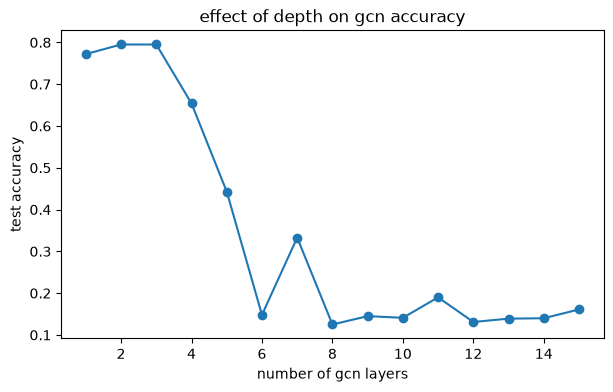

In [28]:
def plot_depth_experiment(layer_range, depth_accuracies):
    plt.figure(figsize=(7, 4))
    plt.plot(layer_range, depth_accuracies, marker="o")
    plt.xlabel("number of gcn layers")
    plt.ylabel("test accuracy")
    plt.title("effect of depth on gcn accuracy")
    plt.show()

plot_depth_experiment(layer_range, depth_accuracies)

a deeper gcn averages every node with a wider neighborhood at every layer, so after many layers all node features start looking similar, and accuracy drops even though the model has more layers to learn with

print a short summary of all the results

In [29]:
def print_summary(scratch_acc, pyg_acc, layer_range, depth_accuracies):
    print("scratch gcn test accuracy:", round(scratch_acc[2], 4))
    print("pyg gcn test accuracy:", round(pyg_acc[2], 4))
    best_layers = layer_range[int(np.argmax(depth_accuracies))]
    print("best number of layers:", best_layers, "with accuracy", round(max(depth_accuracies), 4))

print_summary(scratch_final_acc, pyg_final_acc, layer_range, depth_accuracies)

scratch gcn test accuracy: 0.801
pyg gcn test accuracy: 0.813
best number of layers: 2 with accuracy 0.795
